# RFM customer segmentation

Who are our customers, and which groups deserve attention? This notebook scores every
customer on **recency**, **frequency** and **monetary value** and groups them into
business-readable segments.

**Scoring method.** Each metric is split into quintiles over purchasing customers:

* recency - days since last purchase measured against the fixed analysis end date
  (`2026-09-30`); fewer days scores higher, so the most recent fifth scores 5;
* frequency - recognised (completed) orders; more orders scores higher;
* monetary - recognised net revenue; more revenue scores higher.

Ties are broken by ranking customers in `customer_id` order, so the scores are reproducible.
Customers who never purchased are kept as `Never Purchased` with no scores rather than being
dropped - they are the reactivation universe.

**Revenue definition.** Recognised net merchandise revenue: `items_subtotal - discount_amount`
for completed orders; refunds, cancellations, shipping and VAT excluded.

In [1]:
import pandas as pd
from IPython.display import Image, display

from novacart.analytics.common import load_analysis_inputs
from novacart.analytics.plots import (
    plot_rfm_segment_comparison,
    plot_rfm_segment_customers,
    plot_rfm_segment_revenue,
    save_figure,
    FIGURE_FILENAMES,
)
from novacart.analytics.rfm import (
    SEGMENT_RULES,
    rfm_table,
    segment_score_profile,
    segment_summary,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

## 1. Classification rules

Segments are assigned by the first matching rule, which makes the classification exhaustive
and easy to reproduce. `R`, `F` and `M` are the 1-5 scores.

In [2]:
pd.DataFrame(SEGMENT_RULES, columns=["Segment", "Rule (evaluated in this order)"])

,Segment,Rule (evaluated in this order)
0,Champions,R >= 4 and F >= 4 and M >= 4
1,Loyal Customers,R >= 3 and F >= 3
2,Potential Loyalists,R >= 4 and F >= 2
3,New Customers,R >= 4 and F == 1
4,At Risk,R <= 2 and F >= 3
5,Dormant,R <= 2
6,Needs Attention,all remaining purchasing customers


## 2. Score every customer

In [3]:
inputs = load_analysis_inputs()
rfm = rfm_table(inputs.customers)
print(f"customers scored        : {len(rfm):,}")
print(f"purchasing customers    : {int(rfm['has_purchased'].sum()):,}")
print(f"never purchased         : {int((~rfm['has_purchased']).sum()):,}")

rfm.head(10)[
    ["customer_id", "rfm_segment", "recency_days", "frequency_orders", "monetary_revenue",
     "r_score", "f_score", "m_score", "rfm_cell"]
]

customers scored        : 15,000
purchasing customers    : 7,622
never purchased         : 7,378


,customer_id,rfm_segment,recency_days,frequency_orders,monetary_revenue,r_score,f_score,m_score,rfm_cell
0,CUST-006840,Champions,13.0,80,27957.29,5.0,5.0,5.0,555
1,CUST-003184,Champions,2.0,103,27174.23,5.0,5.0,5.0,555
2,CUST-004175,Champions,3.0,109,26322.23,5.0,5.0,5.0,555
3,CUST-008612,Champions,3.0,92,25633.90,5.0,5.0,5.0,555
4,CUST-002664,Champions,4.0,127,24640.26,5.0,5.0,5.0,555
5,CUST-005205,Champions,0.0,124,23666.44,5.0,5.0,5.0,555
6,CUST-007765,Champions,0.0,130,22822.94,5.0,5.0,5.0,555
7,CUST-001831,Champions,4.0,72,22261.00,5.0,5.0,5.0,555
8,CUST-010978,Champions,2.0,88,22256.96,5.0,5.0,5.0,555
9,CUST-007082,Champions,5.0,69,21780.54,5.0,5.0,5.0,555


## 3. Segment profile

Counts, revenue and repeat behaviour per segment. Revenue share, not just customer count, is
what tells a retention team where to focus.

In [4]:
segments = segment_summary(rfm)
segments.style.format(
    {
        "customers": "{:,.0f}",
        "customer_share_pct": "{:.1f}%",
        "revenue": "EUR {:,.0f}",
        "revenue_share_pct": "{:.1f}%",
        "average_customer_revenue": "EUR {:,.0f}",
        "average_orders": "{:.2f}",
        "average_order_value": "EUR {:,.2f}",
        "average_recency_days": "{:.0f}",
        "repeat_customer_rate": "{:.1%}",
    }
)

,rfm_segment,customers,customer_share_pct,revenue,revenue_share_pct,average_customer_revenue,average_orders,average_order_value,average_recency_days,repeat_customers,repeat_customer_rate
0,Champions,"2,201",14.7%,"EUR 12,582,779",84.7%,"EUR 5,717",30.33,EUR 188.46,14,2201,100.0%
1,Loyal Customers,"1,317",8.8%,"EUR 1,273,054",8.6%,EUR 967,5.13,EUR 188.49,68,1226,93.1%
2,Potential Loyalists,201,1.3%,"EUR 40,680",0.3%,EUR 202,1.00,EUR 202.39,21,0,0.0%
3,New Customers,207,1.4%,"EUR 39,357",0.3%,EUR 190,1.00,EUR 190.13,24,0,0.0%
4,At Risk,"1,055",7.0%,"EUR 429,187",2.9%,EUR 407,2.21,EUR 184.44,322,904,85.7%
5,Needs Attention,647,4.3%,"EUR 121,722",0.8%,EUR 188,1.00,EUR 188.13,97,0,0.0%
6,Dormant,"1,994",13.3%,"EUR 374,730",2.5%,EUR 188,1.00,EUR 187.93,384,0,0.0%
7,Never Purchased,"7,378",49.2%,EUR 0,0.0%,EUR 0,0.00,EUR nan,nan,0,0.0%


In [5]:
profile = segment_score_profile(rfm)
profile.style.format(
    {"customers": "{:,.0f}", "average_r": "{:.2f}", "average_f": "{:.2f}", "average_m": "{:.2f}"}
)

,rfm_segment,customers,average_r,average_f,average_m
0,Champions,"2,201",4.57,4.65,4.65
1,Loyal Customers,"1,317",3.44,3.52,3.11
2,Potential Loyalists,201,4.33,2.00,1.93
3,New Customers,207,4.29,1.00,1.88
4,At Risk,"1,055",1.60,3.24,2.70
5,Needs Attention,647,3.00,1.49,1.86
6,Dormant,"1,994",1.45,1.51,1.86


## 4. Figures

**How large is each segment?**

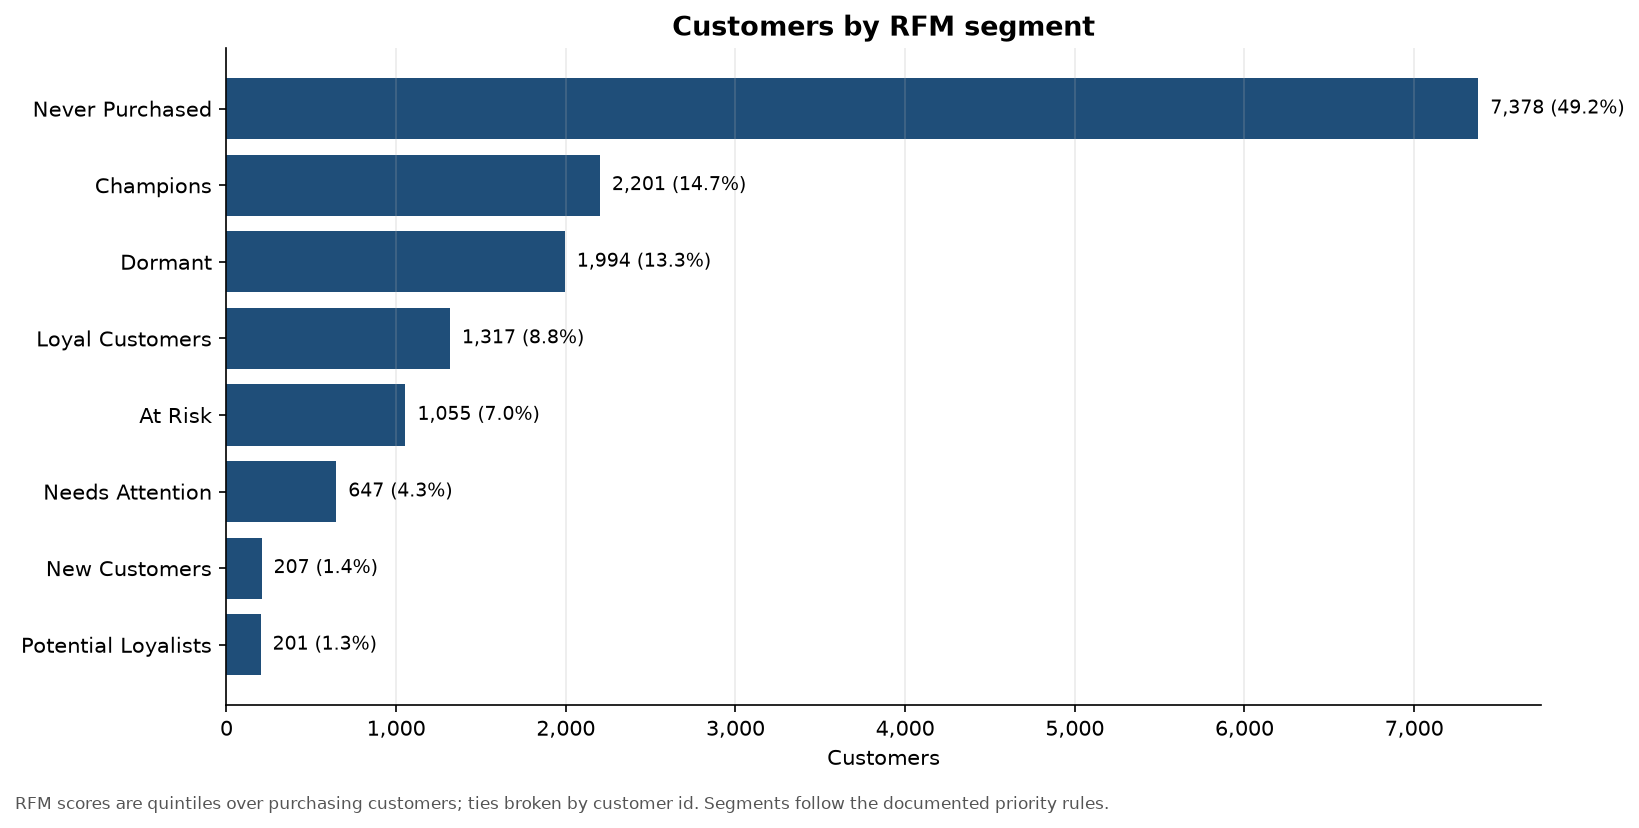

In [6]:
figures = {
    "rfm_customer_counts": save_figure(
        plot_rfm_segment_customers(segments), FIGURE_FILENAMES["rfm_customer_counts"]
    ),
    "rfm_revenue_by_segment": save_figure(
        plot_rfm_segment_revenue(segments), FIGURE_FILENAMES["rfm_revenue_by_segment"]
    ),
    "rfm_segment_comparison": save_figure(
        plot_rfm_segment_comparison(profile), FIGURE_FILENAMES["rfm_segment_comparison"]
    ),
}
display(Image(filename=str(figures["rfm_customer_counts"])))

**Which segments carry the revenue?**

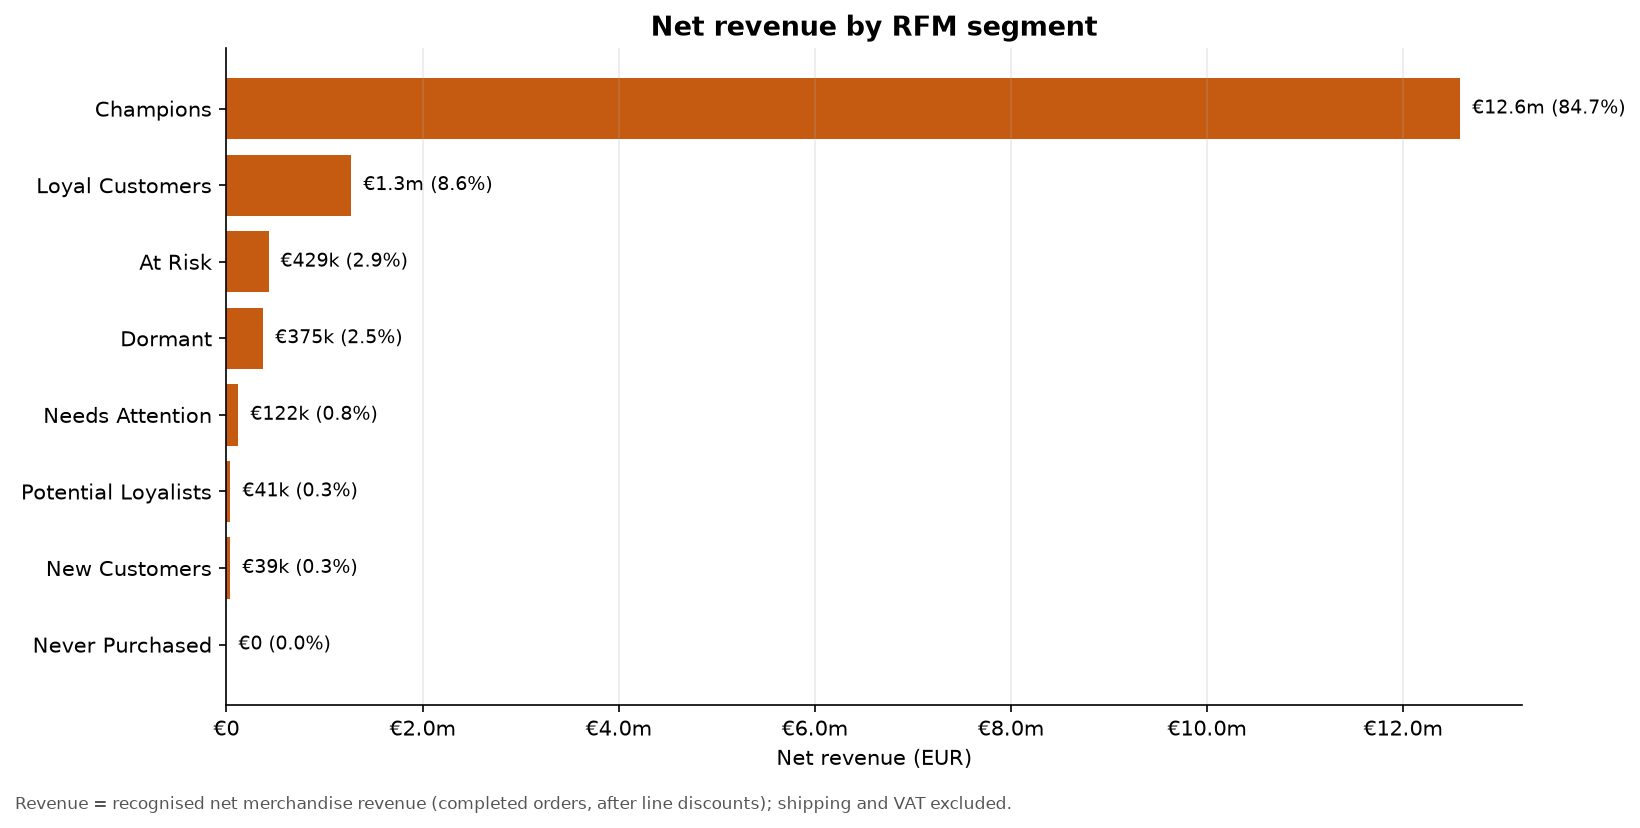

In [7]:
display(Image(filename=str(figures["rfm_revenue_by_segment"])))

**How do the segments differ on the three scores?**

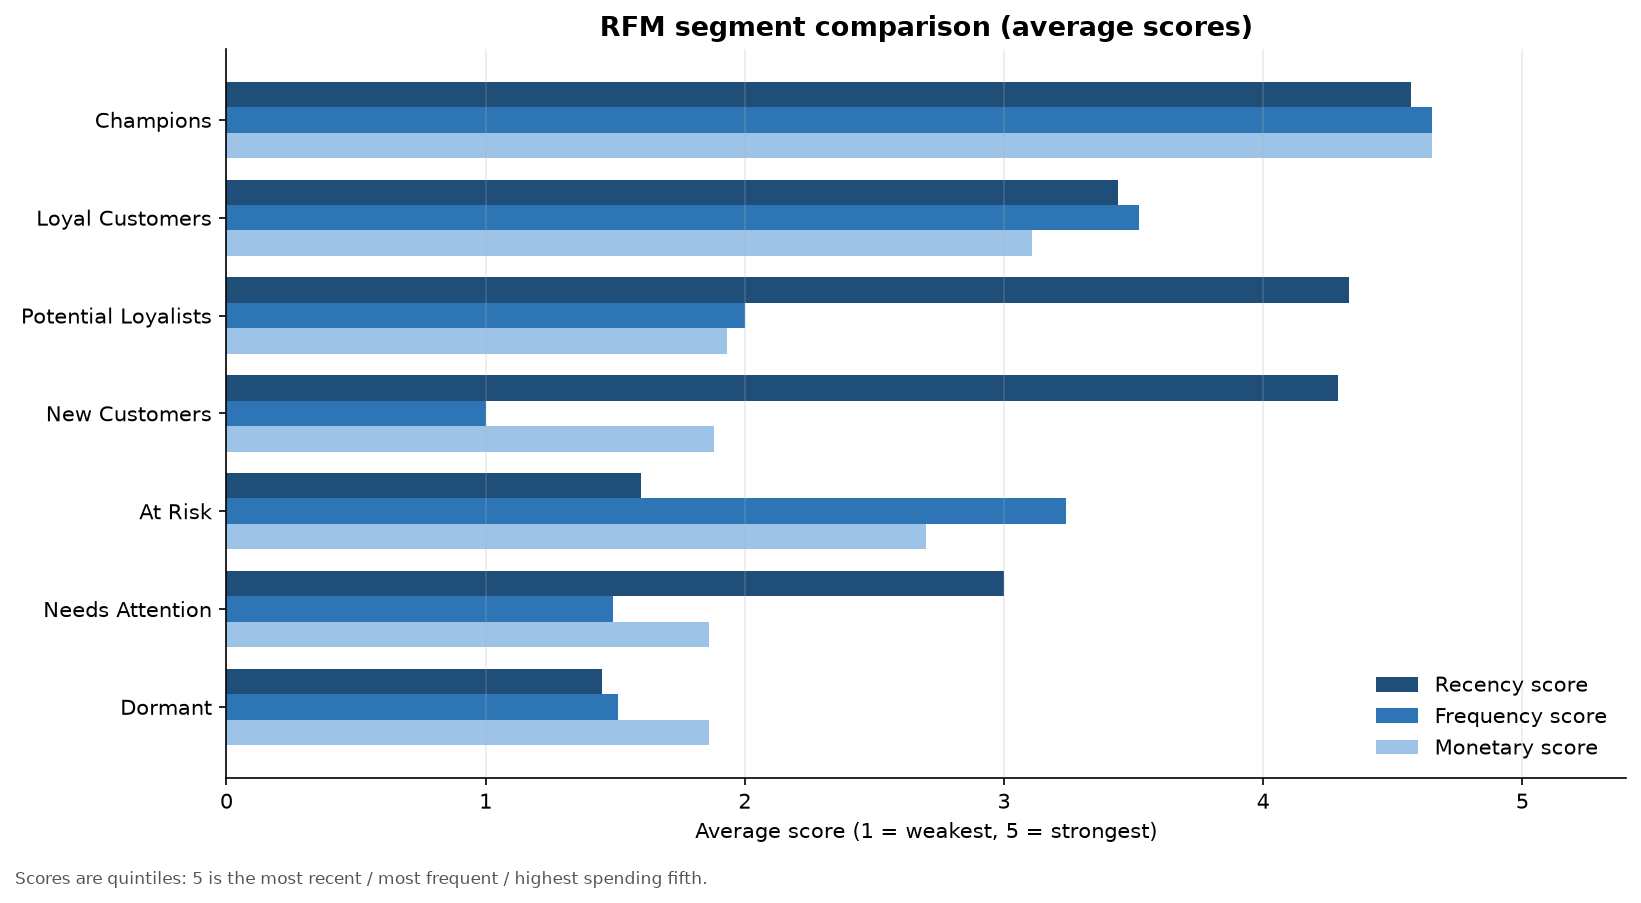

In [8]:
display(Image(filename=str(figures["rfm_segment_comparison"])))

## 5. Reading the segmentation

The tables above answer the operational questions directly:

* **Champions and Loyal Customers** hold the revenue: any change that puts them at risk is a
  revenue event, not a marketing event.
* **At Risk** customers were frequent but have not purchased recently - the clearest
  reactivation target, since they have proven they will buy.
* **New Customers** and **Potential Loyalists** are recent but still low frequency: the
  natural target for onboarding and second-purchase campaigns.
* **Dormant** and **Never Purchased** are the largest groups by count and the smallest by
  revenue; decisions about them should be based on expected value, not volume.

Limitations: RFM is descriptive and relative to this window. Scores are not comparable across
different time windows, the boundaries are quintile-based rather than business-defined, and a
customer's segment can change without any change in behaviour if the customer base shifts.